# PyTorch Tensors: A Practical, Visual Guide

**From the first tensor to broadcasting, matrix algebra, and automatic differentiation**

> A clean, hands-on reference notebook for learning how tensors work in PyTorch. Run the notebook from top to bottom, inspect the outputs, and complete the practice section at the end.

**Level:** Beginner → early intermediate  
**Primary library:** PyTorch (`torch`)  
**Estimated study time:** 2–3 hours, including exercises

---

## Learning outcomes

By the end of this notebook, you should be able to:

- Create tensors from data, ranges, constants, and random distributions.
- Read tensor shape, rank, number of elements, data type, and device.
- Reshape, index, slice, combine, and broadcast tensors safely.
- Apply element-wise arithmetic, reductions, comparisons, and matrix operations.
- Understand common tensor-copying pitfalls and in-place operations.
- Move tensors between CPU and supported accelerators.
- Convert between NumPy arrays and PyTorch tensors.
- Use a small example of automatic differentiation with `autograd`.
- Generate and save clear visualizations in an `images/` directory.

## How to use this notebook

1. Run each code cell in order. Some examples intentionally reuse variables from earlier sections.
2. Read the short explanation before running the code.
3. Change a value or a tensor shape and predict what will happen before rerunning.
4. Keep an eye on **shape**, **dtype**, and **device**. Many tensor bugs begin with one of these being unexpected.

**Installation:** Use the official [PyTorch installation selector](https://pytorch.org/get-started/locally/) to choose the command for your operating system and compute platform. Avoid blindly copying a CUDA-specific command if your machine does not support it.

## Contents

1. Environment setup and reproducibility
2. Tensor mental model: scalar, vector, matrix, and higher dimensions
3. Creating tensors
4. Tensor attributes and shapes
5. Reshaping and combining tensors
6. Indexing, slicing, and masks
7. Data types and devices
8. Arithmetic and broadcasting
9. Reduction operations
10. Matrix and linear-algebra operations
11. Comparisons, sorting, and selection
12. Useful mathematical functions and activations
13. In-place operations
14. Aliasing, views, cloning, and copying
15. NumPy interoperability
16. A first look at automatic differentiation
17. Visualizations saved to `images/`
18. Practical debugging checklist
19. Practice exercises and answer key
20. Quick reference and official resources

# 1. Environment setup and reproducibility

PyTorch tensors are the core data structure used to represent numeric data. They support vectorized arithmetic and can run on different devices, including CPUs and supported GPUs.

This notebook uses only PyTorch, NumPy, and Matplotlib. PyTorch is required; NumPy and Matplotlib are used in the interoperability and plotting sections.

In [1]:
# Core imports
import torch

# NumPy and Matplotlib are used later in this notebook.
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

print(f"PyTorch version: {torch.__version__}")
print(f"NumPy version:   {np.__version__}")
print(f"Matplotlib:      {plt.matplotlib.__version__}")

PyTorch version: 2.11.0+cu130
NumPy version:   2.1.3
Matplotlib:      3.10.0


### Check whether an accelerator is available

The CPU path works on almost any installation. CUDA is available only when the PyTorch build, GPU, drivers, and environment support it. A program should check availability rather than assume that a GPU exists.

In [2]:
if torch.cuda.is_available():
    device = torch.device("cuda")
    print("CUDA is available.")
    print("GPU:", torch.cuda.get_device_name(0))
else:
    device = torch.device("cpu")
    print("CUDA is not available; using CPU.")

print("Selected device:", device)

CUDA is available.
GPU: Tesla T4
Selected device: cuda


### Set a seed for repeatable examples

Random values are useful for demos, initialization, and simulations. A fixed seed makes many random-number examples reproducible within the same software and execution context. It does **not** guarantee identical results across every device, software version, or nondeterministic operation.

In [3]:
torch.manual_seed(42)
random_a = torch.rand(2, 3)

# Reset the seed and generate again.
torch.manual_seed(42)
random_b = torch.rand(2, 3)

print("First sample:\n", random_a)
print("\nRepeated sample:\n", random_b)
print("\nEqual values:", torch.equal(random_a, random_b))

First sample:
 tensor([[0.8823, 0.9150, 0.3829],
        [0.9593, 0.3904, 0.6009]])

Repeated sample:
 tensor([[0.8823, 0.9150, 0.3829],
        [0.9593, 0.3904, 0.6009]])

Equal values: True


# 2. Tensor mental model: scalar, vector, matrix, and higher dimensions

A tensor is a multidimensional array of values. Its **rank** is the number of dimensions, and its **shape** gives the size along each dimension.

| Object | Example shape | Rank |
|---|---:|---:|
| Scalar | `()` | 0 |
| Vector | `(4,)` | 1 |
| Matrix | `(2, 3)` | 2 |
| 3-D tensor | `(2, 3, 4)` | 3 |

In machine learning, a batch of grayscale images might have shape `(batch, height, width)`, while a batch of color images often has shape `(batch, channels, height, width)` in PyTorch workflows.

In [4]:
scalar = torch.tensor(7)
vector = torch.tensor([10, 20, 30, 40])
matrix = torch.tensor([[1, 2, 3], [4, 5, 6]])
tensor_3d = torch.arange(24).reshape(2, 3, 4)

for label, value in [
    ("scalar", scalar),
    ("vector", vector),
    ("matrix", matrix),
    ("3-D tensor", tensor_3d),
]:
    print(f"{label:12} shape={tuple(value.shape)!s:10} rank={value.ndim} elements={value.numel()}")

scalar       shape=()         rank=0 elements=1
vector       shape=(4,)       rank=1 elements=4
matrix       shape=(2, 3)     rank=2 elements=6
3-D tensor   shape=(2, 3, 4)  rank=3 elements=24


### See the values and shapes directly

The `shape` tells you how data is organized, while `numel()` tells you how many values are stored in total. A tensor shaped `(2, 3, 4)` contains `2 × 3 × 4 = 24` elements.

In [5]:
print("Matrix:\n", matrix)
print("\n3-D tensor, with shape", tuple(tensor_3d.shape), ":\n", tensor_3d)

Matrix:
 tensor([[1, 2, 3],
        [4, 5, 6]])

3-D tensor, with shape (2, 3, 4) :
 tensor([[[ 0,  1,  2,  3],
         [ 4,  5,  6,  7],
         [ 8,  9, 10, 11]],

        [[12, 13, 14, 15],
         [16, 17, 18, 19],
         [20, 21, 22, 23]]])


# 3. Creating tensors

Choose the creation function based on the data you already have and the values you need. For a tensor made from ordinary Python data, prefer `torch.tensor(...)`. For shape-based initialization, use functions such as `torch.zeros`, `torch.ones`, or `torch.rand`.

### 3.1 Create a tensor from existing data

Nested lists create multidimensional tensors. By default, integer input commonly becomes `torch.int64`, while floating-point input commonly becomes `torch.float32`. The selected dtype can be specified explicitly.

In [6]:
from_list = torch.tensor([1, 2, 3, 4])
from_nested_list = torch.tensor([[1, 2, 3], [4, 5, 6]])
from_floats = torch.tensor([1.2, 2.5, 3.7], dtype=torch.float32)

print("Vector:\n", from_list)
print("\nMatrix:\n", from_nested_list)
print("\nFloat tensor:", from_floats)

Vector:
 tensor([1, 2, 3, 4])

Matrix:
 tensor([[1, 2, 3],
        [4, 5, 6]])

Float tensor: tensor([1.2000, 2.5000, 3.7000])


### 3.2 Fill tensors with constants

Use these functions when you know the required shape and want predictable initial values.

In [7]:
zeros = torch.zeros((2, 3))
ones = torch.ones((2, 3))
filled = torch.full((2, 3), fill_value=9)
identity = torch.eye(3)

print("zeros:\n", zeros)
print("\nones:\n", ones)
print("\nfull of 9s:\n", filled)
print("\n3 × 3 identity matrix:\n", identity)

zeros:
 tensor([[0., 0., 0.],
        [0., 0., 0.]])

ones:
 tensor([[1., 1., 1.],
        [1., 1., 1.]])

full of 9s:
 tensor([[9, 9, 9],
        [9, 9, 9]])

3 × 3 identity matrix:
 tensor([[1., 0., 0.],
        [0., 1., 0.],
        [0., 0., 1.]])


### 3.3 Create ranges and evenly spaced values

- `torch.arange(start, stop, step)` uses a step size; the stop value is excluded.
- `torch.linspace(start, end, steps)` returns a specified number of evenly spaced values, including the endpoints in the usual case where `steps > 1`.

In [8]:
range_values = torch.arange(0, 12, 2)
spaced_values = torch.linspace(0, 1, steps=6)

print("arange(0, 12, 2):", range_values)
print("linspace(0, 1, 6):", spaced_values)

arange(0, 12, 2): tensor([ 0,  2,  4,  6,  8, 10])
linspace(0, 1, 6): tensor([0.0000, 0.2000, 0.4000, 0.6000, 0.8000, 1.0000])


### 3.4 Random tensors

`rand` samples from a uniform distribution on `[0, 1)`, `randn` samples from a standard normal distribution, and `randint` generates integers from a specified range. Use a seed when repeatable examples matter.

In [9]:
torch.manual_seed(7)
uniform_values = torch.rand(2, 3)
normal_values = torch.randn(2, 3)
integer_values = torch.randint(low=0, high=10, size=(2, 3))

print("Uniform random values:\n", uniform_values)
print("\nStandard normal values:\n", normal_values)
print("\nRandom integers from 0 to 9:\n", integer_values)

Uniform random values:
 tensor([[0.5349, 0.1988, 0.6592],
        [0.6569, 0.2328, 0.4251]])

Standard normal values:
 tensor([[-1.2514, -1.8841,  0.4457],
        [-0.7068, -1.5750, -0.6318]])

Random integers from 0 to 9:
 tensor([[3, 8, 6],
        [0, 5, 1]])


### 3.5 Create a tensor like another tensor

The `*_like` functions reuse an existing tensor's shape. They usually preserve its dtype unless you override it.

In [10]:
reference = torch.tensor([[1, 2, 3], [4, 5, 6]], dtype=torch.float32)

print("reference:\n", reference)
print("\nzeros_like:\n", torch.zeros_like(reference))
print("\nones_like:\n", torch.ones_like(reference))
print("\nrand_like:\n", torch.rand_like(reference))
print("\nempty_like shape:", torch.empty_like(reference).shape)

reference:
 tensor([[1., 2., 3.],
        [4., 5., 6.]])

zeros_like:
 tensor([[0., 0., 0.],
        [0., 0., 0.]])

ones_like:
 tensor([[1., 1., 1.],
        [1., 1., 1.]])

rand_like:
 tensor([[0.5209, 0.5932, 0.8797],
        [0.6286, 0.7653, 0.1132]])

empty_like shape: torch.Size([2, 3])


> **Important — `torch.empty`:** `torch.empty(shape)` allocates memory without initializing the values. The returned values may look random because they are whatever bits happen to be present in that memory. Do not use `empty` when you need known starting values; choose `zeros`, `ones`, or another initialized constructor instead.

In [11]:
uninitialized = torch.empty((2, 3))
print("Allocated shape:", tuple(uninitialized.shape))
print("The values are intentionally not interpreted here.")

Allocated shape: (2, 3)
The values are intentionally not interpreted here.


# 4. Tensor attributes and shapes

The attributes below are among the most useful first checks when debugging tensor code.

In [12]:
sample = torch.tensor([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])

print("Values:\n", sample)
print("shape:", sample.shape)
print("rank / ndim:", sample.ndim)
print("number of elements:", sample.numel())
print("dtype:", sample.dtype)
print("device:", sample.device)
print("requires_grad:", sample.requires_grad)

Values:
 tensor([[1., 2., 3.],
        [4., 5., 6.]])
shape: torch.Size([2, 3])
rank / ndim: 2
number of elements: 6
dtype: torch.float32
device: cpu
requires_grad: False


### Shape arithmetic before reshaping

A reshape can change the arrangement of values, but not the number of elements. Before reshaping, check the total element count. For example, a 2 × 3 matrix can be reshaped to 3 × 2 because both contain six values.

In [13]:
print("Original shape:", tuple(sample.shape))
print("Number of elements:", sample.numel())
print("Reshaped to (3, 2):\n", sample.reshape(3, 2))

# This would fail because 2 × 4 = 8, not 6:
# sample.reshape(2, 4)

Original shape: (2, 3)
Number of elements: 6
Reshaped to (3, 2):
 tensor([[1., 2.],
        [3., 4.],
        [5., 6.]])


# 5. Reshaping and combining tensors

Changing shape is common when moving between raw data, batches, neural-network layers, and outputs. Each operation below serves a slightly different purpose.

### 5.1 `reshape`, `view`, and `flatten`

- `reshape` returns a tensor with the requested shape; it may return a view or make a copy as needed.
- `view` returns a view when the tensor's memory layout supports the requested shape.
- `flatten` collapses a range of dimensions into one dimension.

In [14]:
base = torch.arange(12)
reshaped = base.reshape(3, 4)
viewed = base.view(2, 6)
flattened = reshaped.flatten()

print("base:", base)
print("\nreshape(3, 4):\n", reshaped)
print("\nview(2, 6):\n", viewed)
print("\nflatten():", flattened)

base: tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])

reshape(3, 4):
 tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])

view(2, 6):
 tensor([[ 0,  1,  2,  3,  4,  5],
        [ 6,  7,  8,  9, 10, 11]])

flatten(): tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])


### 5.2 Add and remove dimensions

`unsqueeze(dim)` inserts a dimension of size 1. `squeeze()` removes dimensions of size 1. These are useful when adding a batch or channel dimension, but inspect the result to make sure the intended axis changed.

In [15]:
one_d = torch.tensor([10, 20, 30])
with_leading_axis = one_d.unsqueeze(0)
with_trailing_axis = one_d.unsqueeze(1)

print("one_d:", tuple(one_d.shape))
print("unsqueeze(0):", tuple(with_leading_axis.shape))
print("unsqueeze(1):", tuple(with_trailing_axis.shape))
print("squeeze back:", tuple(with_trailing_axis.squeeze().shape))

one_d: (3,)
unsqueeze(0): (1, 3)
unsqueeze(1): (3, 1)
squeeze back: (3,)


### 5.3 Transpose and permute axes

For a 2-D tensor, `transpose(0, 1)` swaps rows and columns. For tensors with more dimensions, `permute(...)` specifies the new order of all axes.

In [16]:
matrix_for_transpose = torch.arange(6).reshape(2, 3)
print("Original (2, 3):\n", matrix_for_transpose)
print("\nTransposed (3, 2):\n", matrix_for_transpose.transpose(0, 1))

image_like = torch.arange(24).reshape(2, 3, 4)
permuted = image_like.permute(2, 0, 1)
print("\nOriginal 3-D shape:", tuple(image_like.shape))
print("Permuted shape:", tuple(permuted.shape))

Original (2, 3):
 tensor([[0, 1, 2],
        [3, 4, 5]])

Transposed (3, 2):
 tensor([[0, 3],
        [1, 4],
        [2, 5]])

Original 3-D shape: (2, 3, 4)
Permuted shape: (4, 2, 3)


### 5.4 Stack versus concatenate

- `torch.stack` adds a **new** dimension; all input tensors must have the same shape.
- `torch.cat` joins tensors along an **existing** dimension; other dimensions must match.

In [17]:
row_a = torch.tensor([1, 2, 3])
row_b = torch.tensor([4, 5, 6])

print("stack along dim=0:\n", torch.stack((row_a, row_b), dim=0))
print("\nstack shape:", tuple(torch.stack((row_a, row_b), dim=0).shape))
print("\nconcatenate along dim=0:", torch.cat((row_a, row_b), dim=0))

col_a = row_a.reshape(3, 1)
col_b = row_b.reshape(3, 1)
print("\ncat columns shape:", tuple(torch.cat((col_a, col_b), dim=1).shape))

stack along dim=0:
 tensor([[1, 2, 3],
        [4, 5, 6]])

stack shape: (2, 3)

concatenate along dim=0: tensor([1, 2, 3, 4, 5, 6])

cat columns shape: (3, 2)


# 6. Indexing, slicing, and masks

Indexing follows Python's zero-based convention. For a 2-D tensor, `tensor[row, column]` selects one element; a slice selects a range. A boolean mask selects elements where the condition is `True`.

In [18]:
grid = torch.arange(1, 13).reshape(3, 4)
print("Grid:\n", grid)
print("\nElement at row 0, column 2:", grid[0, 2])
print("First row:", grid[0, :])
print("Last column:\n", grid[:, -1])
print("Rows 0–1, columns 1–2:\n", grid[0:2, 1:3])

Grid:
 tensor([[ 1,  2,  3,  4],
        [ 5,  6,  7,  8],
        [ 9, 10, 11, 12]])

Element at row 0, column 2: tensor(3)
First row: tensor([1, 2, 3, 4])
Last column:
 tensor([ 4,  8, 12])
Rows 0–1, columns 1–2:
 tensor([[2, 3],
        [6, 7]])


### Boolean masks

A comparison creates a boolean tensor. That mask can be used to filter values or replace selected elements. In the example below, all values greater than 6 are selected.

In [19]:
mask = grid > 6
print("Mask (True means the condition holds):\n", mask)
print("\nValues greater than 6:", grid[mask])
print("\nReplace values <= 6 with zero:\n", torch.where(grid > 6, grid, torch.zeros_like(grid)))

Mask (True means the condition holds):
 tensor([[False, False, False, False],
        [False, False,  True,  True],
        [ True,  True,  True,  True]])

Values greater than 6: tensor([ 7,  8,  9, 10, 11, 12])

Replace values <= 6 with zero:
 tensor([[ 0,  0,  0,  0],
        [ 0,  0,  7,  8],
        [ 9, 10, 11, 12]])


### Avoid accidental mutation through indexed assignment

Tensor assignment updates the selected location in the original tensor. This can be useful, but it also means that a small indexing operation may change data used later.

In [20]:
mutable = torch.tensor([[1, 2], [3, 4]])
mutable[0, 0] = 99
print(mutable)

tensor([[99,  2],
        [ 3,  4]])


# 7. Data types and devices

A tensor's `dtype` controls how its values are represented in memory. A tensor's `device` controls where the data lives. Arithmetic usually requires compatible dtypes and devices.

### Common data types

| PyTorch dtype | Typical use | Notes |
|---|---|---|
| `torch.float32` | General model inputs and computation | Common default for floating-point model data |
| `torch.float64` | Higher-precision numerical work | Uses more memory than float32 |
| `torch.float16` | Reduced-precision GPU computation | Range/precision trade-offs; often used in mixed precision |
| `torch.bfloat16` | Reduced-precision model computation | Wider exponent range than float16 on supported hardware |
| `torch.int64` | Integer indices and labels in many workflows | Also called `long` |
| `torch.int32` | 32-bit integer data | Use when the operation expects or benefits from it |
| `torch.bool` | Boolean masks | Holds `True` / `False` |

The accepted dtype depends on the operation. For example, many neural-network losses expect floating-point model outputs and integer class-index targets.

In [21]:
integer_tensor = torch.tensor([1, 2, 3])
float_tensor = torch.tensor([1.0, 2.0, 3.0])
boolean_tensor = torch.tensor([True, False, True])

print("Integer dtype:", integer_tensor.dtype)
print("Float dtype:", float_tensor.dtype)
print("Boolean dtype:", boolean_tensor.dtype)

Integer dtype: torch.int64
Float dtype: torch.float32
Boolean dtype: torch.bool


### Convert a tensor's dtype

Use `.to(...)` or the convenience methods such as `.float()` when a conversion is appropriate. Casting a floating-point tensor to an integer dtype discards the fractional part rather than rounding to the nearest integer.

In [22]:
values = torch.tensor([1.7, 2.2, 3.9])

as_float64 = values.to(torch.float64)
as_int64 = values.to(torch.int64)

print("Original:", values, values.dtype)
print("Float64:", as_float64, as_float64.dtype)
print("Int64 (fractional part discarded):", as_int64, as_int64.dtype)

Original: tensor([1.7000, 2.2000, 3.9000]) torch.float32
Float64: tensor([1.7000, 2.2000, 3.9000], dtype=torch.float64) torch.float64
Int64 (fractional part discarded): tensor([1, 2, 3]) torch.int64


### Move tensors to a device

The selected `device` was set near the beginning of this notebook. Use `.to(device)` to place a tensor there. Models and the data passed to them generally need to be on compatible devices.

In [23]:
cpu_values = torch.arange(6, dtype=torch.float32).reshape(2, 3)
device_values = cpu_values.to(device)

print("CPU tensor device:", cpu_values.device)
print("Selected tensor device:", device_values.device)
print("Same values after move:\n", device_values)

CPU tensor device: cpu
Selected tensor device: cuda:0
Same values after move:
 tensor([[0., 1., 2.],
        [3., 4., 5.]], device='cuda:0')


> **Best practice:** Keep a clear convention for device and dtype in a project. If you see an error about a CPU/CUDA mismatch, inspect `.device` on every tensor involved in the operation.

# 8. Arithmetic and broadcasting

Most basic arithmetic operators on tensors are **element-wise**. Each value in one tensor is combined with the corresponding value in the other tensor. For matrix multiplication, use a matrix operation such as `@` or `torch.matmul` instead.

### 8.1 Scalar arithmetic

A scalar can be broadcast across every element of a tensor.

In [24]:
x = torch.tensor([[1.0, 2.0], [3.0, 4.0]])

print("x:\n", x)
print("\nx + 2:\n", x + 2)
print("\nx - 2:\n", x - 2)
print("\nx * 3:\n", x * 3)
print("\nx / 2:\n", x / 2)
print("\nx squared:\n", x ** 2)

x:
 tensor([[1., 2.],
        [3., 4.]])

x + 2:
 tensor([[3., 4.],
        [5., 6.]])

x - 2:
 tensor([[-1.,  0.],
        [ 1.,  2.]])

x * 3:
 tensor([[ 3.,  6.],
        [ 9., 12.]])

x / 2:
 tensor([[0.5000, 1.0000],
        [1.5000, 2.0000]])

x squared:
 tensor([[ 1.,  4.],
        [ 9., 16.]])


### 8.2 Element-wise operations

The two tensors below have identical shapes, so their values are combined position by position.

In [25]:
a = torch.tensor([[12.0, 18.0], [24.0, 30.0]])
b = torch.tensor([[3.0, 6.0], [4.0, 5.0]])

print("a + b:\n", a + b)
print("\na - b:\n", a - b)
print("\na * b (element-wise):\n", a * b)
print("\na / b:\n", a / b)
print("\na % b:\n", a % b)

a + b:
 tensor([[15., 24.],
        [28., 35.]])

a - b:
 tensor([[ 9., 12.],
        [20., 25.]])

a * b (element-wise):
 tensor([[ 36., 108.],
        [ 96., 150.]])

a / b:
 tensor([[4., 3.],
        [6., 6.]])

a % b:
 tensor([[0., 0.],
        [0., 0.]])


### 8.3 Broadcasting

Broadcasting lets PyTorch combine compatible shapes without manually repeating values. Dimensions are compared from the right; each pair must be equal or one of them must be 1. A shape of `(2, 3)` can broadcast with `(3,)`, because the vector aligns with the final dimension.

In [26]:
matrix = torch.tensor([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])
row_vector = torch.tensor([10.0, 20.0, 30.0])

print("Matrix shape:", tuple(matrix.shape))
print("Vector shape:", tuple(row_vector.shape))
print("\nMatrix + row vector:\n", matrix + row_vector)

Matrix shape: (2, 3)
Vector shape: (3,)

Matrix + row vector:
 tensor([[11., 22., 33.],
        [14., 25., 36.]])


### Broadcasting by adding an axis

A column vector shaped `(2, 1)` can broadcast across the columns of a matrix shaped `(2, 3)`. Be explicit about dimensions when the intended alignment is not obvious.

In [27]:
column_vector = torch.tensor([[100.0], [200.0]])
print("Column shape:", tuple(column_vector.shape))
print("Broadcast result:\n", matrix + column_vector)

Column shape: (2, 1)
Broadcast result:
 tensor([[101., 102., 103.],
        [204., 205., 206.]])


### Rounding, absolute value, and clamping

These functions are common when cleaning values, enforcing bounds, and preparing values for downstream operations.

In [28]:
numbers = torch.tensor([-2.4, -0.5, 1.2, 2.7, 4.4])
print("numbers:", numbers)
print("absolute:", torch.abs(numbers))
print("round:", torch.round(numbers))
print("ceil:", torch.ceil(numbers))
print("floor:", torch.floor(numbers))
print("clamp to [-1, 3]:", torch.clamp(numbers, min=-1, max=3))

numbers: tensor([-2.4000, -0.5000,  1.2000,  2.7000,  4.4000])
absolute: tensor([2.4000, 0.5000, 1.2000, 2.7000, 4.4000])
round: tensor([-2., -0.,  1.,  3.,  4.])
ceil: tensor([-2., -0.,  2.,  3.,  5.])
floor: tensor([-3., -1.,  1.,  2.,  4.])
clamp to [-1, 3]: tensor([-1.0000, -0.5000,  1.2000,  2.7000,  3.0000])


# 9. Reduction operations

A reduction condenses values into a smaller result, for example a sum, average, maximum, or standard deviation. The `dim` parameter controls which axis is reduced.

In [29]:
scores = torch.tensor([[2.0, 5.0, 8.0], [1.0, 4.0, 7.0]])
print("Scores:\n", scores)
print("\nTotal sum:", torch.sum(scores))
print("Mean of all values:", torch.mean(scores))
print("Maximum value:", torch.max(scores))
print("Minimum value:", torch.min(scores))

Scores:
 tensor([[2., 5., 8.],
        [1., 4., 7.]])

Total sum: tensor(27.)
Mean of all values: tensor(4.5000)
Maximum value: tensor(8.)
Minimum value: tensor(1.)


### Understand `dim`

For a matrix with shape `(rows, columns)`:

- `dim=0` reduces down the rows, leaving one result per column.
- `dim=1` reduces across the columns, leaving one result per row.

This convention is easiest to remember by checking the output shape.

In [30]:
print("Column sums (dim=0):", scores.sum(dim=0))
print("Row sums (dim=1):", scores.sum(dim=1))
print("Column means (dim=0):", scores.mean(dim=0))
print("Row means (dim=1):", scores.mean(dim=1))
print("\nOriginal shape:", tuple(scores.shape))
print("Sum with dim=1, keepdim=True shape:", tuple(scores.sum(dim=1, keepdim=True).shape))

Column sums (dim=0): tensor([ 3.,  9., 15.])
Row sums (dim=1): tensor([15., 12.])
Column means (dim=0): tensor([1.5000, 4.5000, 7.5000])
Row means (dim=1): tensor([5., 4.])

Original shape: (2, 3)
Sum with dim=1, keepdim=True shape: (2, 1)


### Other useful reductions

`prod` multiplies values, `std` computes standard deviation, and `var` computes variance. PyTorch's default variance/std settings use a correction; for a population statistic, choose the correction explicitly when appropriate for the task.

In [31]:
measurements = torch.tensor([2.0, 4.0, 4.0, 4.0, 5.0, 5.0, 7.0, 9.0])
print("Product:", torch.prod(measurements))
print("Standard deviation (default correction):", torch.std(measurements))
print("Variance (default correction):", torch.var(measurements))
print("Population variance (correction=0):", torch.var(measurements, correction=0))

Product: tensor(201600.)
Standard deviation (default correction): tensor(2.1381)
Variance (default correction): tensor(4.5714)
Population variance (correction=0): tensor(4.)


### Retrieve the index of an extreme value

`argmax` and `argmin` return index positions, not the maximum/minimum values themselves. Use `dim` to find an index along a specific axis.

In [32]:
predictions = torch.tensor([[0.10, 0.70, 0.20], [0.65, 0.15, 0.20]])
print("Predictions:\n", predictions)
print("Flat argmax index:", torch.argmax(predictions))
print("Highest-scoring class for each row:", torch.argmax(predictions, dim=1))
print("Maximum value in each row:", torch.max(predictions, dim=1).values)

Predictions:
 tensor([[0.1000, 0.7000, 0.2000],
        [0.6500, 0.1500, 0.2000]])
Flat argmax index: tensor(1)
Highest-scoring class for each row: tensor([1, 0])
Maximum value in each row: tensor([0.7000, 0.6500])


# 10. Matrix and linear-algebra operations

Element-wise multiplication is different from matrix multiplication. Matrix multiplication combines rows and columns, and the **inner dimensions must match**. For shapes `(m, n)` and `(n, p)`, the result has shape `(m, p)`.

### 10.1 Matrix multiplication

Use `@` or `torch.matmul` for standard matrix multiplication.

In [33]:
left = torch.tensor([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])   # (2, 3)
right = torch.tensor([[1.0, 2.0], [3.0, 4.0], [5.0, 6.0]])  # (3, 2)

product = left @ right
print("Left shape:", tuple(left.shape))
print("Right shape:", tuple(right.shape))
print("Product shape:", tuple(product.shape))
print("\nProduct:\n", product)
print("\nMatches torch.matmul:", torch.equal(product, torch.matmul(left, right)))

Left shape: (2, 3)
Right shape: (3, 2)
Product shape: (2, 2)

Product:
 tensor([[22., 28.],
        [49., 64.]])

Matches torch.matmul: True


### 10.2 Dot product and transpose

The dot product multiplies corresponding vector values and sums them. Transposition swaps two dimensions.

In [34]:
vector_a = torch.tensor([1.0, 2.0, 3.0])
vector_b = torch.tensor([4.0, 5.0, 6.0])
print("Dot product:", torch.dot(vector_a, vector_b))

rectangular = torch.arange(6).reshape(2, 3)
print("\nOriginal:\n", rectangular)
print("\nTranspose:\n", rectangular.T)

Dot product: tensor(32.)

Original:
 tensor([[0, 1, 2],
        [3, 4, 5]])

Transpose:
 tensor([[0, 3],
        [1, 4],
        [2, 5]])


### 10.3 Determinant and inverse

Determinants and inverses apply to square matrices. An inverse exists only for a nonsingular matrix. In numerical work, prefer solving a system with `torch.linalg.solve(A, b)` over explicitly computing `A^{-1} b`.

In [35]:
square = torch.tensor([[4.0, 7.0], [2.0, 6.0]])
determinant = torch.linalg.det(square)
inverse = torch.linalg.inv(square)

print("Matrix:\n", square)
print("Determinant:", determinant)
print("Inverse:\n", inverse)
print("\nA @ inverse(A), approximately identity:\n", square @ inverse)

rhs = torch.tensor([1.0, 0.0])
print("\nSolution to A @ solution = rhs:", torch.linalg.solve(square, rhs))

Matrix:
 tensor([[4., 7.],
        [2., 6.]])
Determinant: tensor(10.0000)
Inverse:
 tensor([[ 0.6000, -0.7000],
        [-0.2000,  0.4000]])

A @ inverse(A), approximately identity:
 tensor([[1.0000, 0.0000],
        [0.0000, 1.0000]])

Solution to A @ solution = rhs: tensor([ 0.6000, -0.2000])


# 11. Comparisons, sorting, and selection

Comparison operators create boolean tensors. These masks can be used to filter values, choose between two tensors, or count the number of values meeting a condition.

In [36]:
left_values = torch.tensor([[2, 5, 8], [3, 6, 9]])
right_values = torch.tensor([[4, 5, 7], [3, 1, 9]])

print("left > right:\n", left_values > right_values)
print("\nleft == right:\n", left_values == right_values)
print("\nleft != right:\n", left_values != right_values)
print("\nHow many entries in left are greater than 5?", (left_values > 5).sum().item())

left > right:
 tensor([[False, False,  True],
        [False,  True, False]])

left == right:
 tensor([[False,  True, False],
        [ True, False,  True]])

left != right:
 tensor([[ True, False,  True],
        [False,  True, False]])

How many entries in left are greater than 5? 3


### `where`, sorting, and top-k values

`torch.where(condition, x, y)` selects from `x` where the condition is true and from `y` otherwise. Sorting and top-k operations are useful for ranking outputs.

In [37]:
values = torch.tensor([7.0, 2.0, 9.0, 4.0, 6.0])
selected = torch.where(values >= 5, values, torch.zeros_like(values))

print("Original:", values)
print("Keep values >= 5, otherwise zero:", selected)
print("Sorted ascending:", torch.sort(values).values)
top_values, top_indices = torch.topk(values, k=3)
print("Top 3 values:", top_values)
print("Their original indices:", top_indices)

Original: tensor([7., 2., 9., 4., 6.])
Keep values >= 5, otherwise zero: tensor([7., 0., 9., 0., 6.])
Sorted ascending: tensor([2., 4., 6., 7., 9.])
Top 3 values: tensor([9., 7., 6.])
Their original indices: tensor([2, 0, 4])


# 12. Useful mathematical functions and activations

PyTorch includes common functions used in data processing and neural networks. Be mindful of each function's domain: for instance, the natural logarithm expects positive inputs for finite real-valued results.

In [38]:
positive_values = torch.tensor([1.0, 2.0, 4.0, 9.0])
print("log:", torch.log(positive_values))
print("exp:", torch.exp(positive_values))
print("sqrt:", torch.sqrt(positive_values))

log: tensor([0.0000, 0.6931, 1.3863, 2.1972])
exp: tensor([2.7183e+00, 7.3891e+00, 5.4598e+01, 8.1031e+03])
sqrt: tensor([1.0000, 1.4142, 2.0000, 3.0000])


### Common activation functions

- **ReLU:** replaces negative values with zero.
- **Sigmoid:** maps values to the interval `(0, 1)`.
- **Softmax:** transforms values into a distribution along the selected dimension, so that entries along that dimension sum to 1. For numerical stability, use `torch.softmax` rather than implementing the formula manually.

In [39]:
activation_input = torch.tensor([[-2.0, -0.5, 0.0, 1.0, 3.0]])
print("Input:", activation_input)
print("ReLU:", torch.relu(activation_input))
print("Sigmoid:", torch.sigmoid(activation_input))

logits = torch.tensor([[2.0, 1.0, 0.1], [0.2, 0.3, 0.5]])
probabilities = torch.softmax(logits, dim=1)
print("\nLogits:\n", logits)
print("Softmax across classes (dim=1):\n", probabilities)
print("Row sums:", probabilities.sum(dim=1))

Input: tensor([[-2.0000, -0.5000,  0.0000,  1.0000,  3.0000]])
ReLU: tensor([[0., 0., 0., 1., 3.]])
Sigmoid: tensor([[0.1192, 0.3775, 0.5000, 0.7311, 0.9526]])

Logits:
 tensor([[2.0000, 1.0000, 0.1000],
        [0.2000, 0.3000, 0.5000]])
Softmax across classes (dim=1):
 tensor([[0.6590, 0.2424, 0.0986],
        [0.2894, 0.3199, 0.3907]])
Row sums: tensor([1.0000, 1.0000])


### Why the `dim` parameter matters for softmax

For a batch of classification scores shaped `(batch_size, classes)`, `dim=1` normalizes over classes within each example. `dim=0` instead normalizes each class column across the batch, which is usually not the desired class-probability interpretation.

In [40]:
softmax_over_classes = torch.softmax(logits, dim=1)
softmax_over_batch = torch.softmax(logits, dim=0)

print("Sum across each row (classes):", softmax_over_classes.sum(dim=1))
print("Sum down each column (batch):", softmax_over_batch.sum(dim=0))

Sum across each row (classes): tensor([1.0000, 1.0000])
Sum down each column (batch): tensor([1.0000, 1.0000, 1.0000])


# 13. In-place operations

An in-place method changes the existing tensor rather than returning only a new result. PyTorch operations with a trailing underscore commonly follow this convention, such as `add_()` and `relu_()`.

In-place updates can be efficient, but they can make a program harder to reason about and may conflict with values needed by automatic differentiation. Use them deliberately.

In [41]:
base = torch.tensor([[1.0, -2.0], [3.0, -4.0]])
addition = torch.ones_like(base)

print("Before add_():\n", base)
base.add_(addition)
print("\nAfter add_():\n", base)

base.relu_()
print("\nAfter relu_():\n", base)

Before add_():
 tensor([[ 1., -2.],
        [ 3., -4.]])

After add_():
 tensor([[ 2., -1.],
        [ 4., -3.]])

After relu_():
 tensor([[2., 0.],
        [4., 0.]])


### Compare an out-of-place and in-place operation

The out-of-place `torch.relu(tensor)` returns a result and leaves the input unchanged. `tensor.relu_()` overwrites the input.

In [42]:
original = torch.tensor([-2.0, 1.0, -4.0])
result = torch.relu(original)
print("Original remains:", original)
print("Out-of-place result:", result)

original.relu_()
print("Original after in-place relu_:", original)

Original remains: tensor([-2.,  1., -4.])
Out-of-place result: tensor([0., 1., 0.])
Original after in-place relu_: tensor([0., 1., 0.])


# 14. Aliasing, views, cloning, and copying

One of the most important tensor concepts is understanding whether two variables refer to the same underlying data. A Python assignment such as `b = a` does not create an independent tensor copy; both names refer to the same tensor object.

In [43]:
a = torch.tensor([[1, 2], [3, 4]])
b = a

print("a is b:", a is b)
print("id(a):", id(a))
print("id(b):", id(b))

b[0, 0] = 99
print("\na after changing b:\n", a)
print("b after changing b:\n", b)

a is b: True
id(a): 134066955390800
id(b): 134066955390800

a after changing b:
 tensor([[99,  2],
        [ 3,  4]])
b after changing b:
 tensor([[99,  2],
        [ 3,  4]])


### Make an independent copy with `clone`

`clone()` creates a new tensor with its own data storage. A clone can still participate in autograd if the source tensor requires gradients; use `detach()` when you specifically need to break the gradient connection.

In [44]:
source = torch.tensor([[1.0, 2.0], [3.0, 4.0]])
independent_copy = source.clone()

independent_copy[0, 0] = -100
print("Source stays unchanged:\n", source)
print("Modified clone:\n", independent_copy)
print("Same Python object:", source is independent_copy)

Source stays unchanged:
 tensor([[1., 2.],
        [3., 4.]])
Modified clone:
 tensor([[-100.,    2.],
        [   3.,    4.]])
Same Python object: False


### Views and reshaped data

Some operations, such as slicing or a compatible `view`, may return a view that shares storage with the original tensor. Modifying a view can therefore affect the source. When independent values are required, make an explicit clone.

In [45]:
source = torch.arange(6)
view_of_source = source[1:4]
print("Source before:", source)
print("Slice view:", view_of_source)

view_of_source[0] = 99
print("Source after editing the view:", source)

safe_copy = source[1:4].clone()
safe_copy[0] = -5
print("Source after editing a clone:", source)
print("Clone:", safe_copy)

Source before: tensor([0, 1, 2, 3, 4, 5])
Slice view: tensor([1, 2, 3])
Source after editing the view: tensor([ 0, 99,  2,  3,  4,  5])
Source after editing a clone: tensor([ 0, 99,  2,  3,  4,  5])
Clone: tensor([-5,  2,  3])


# 15. NumPy interoperability

PyTorch and NumPy can exchange data efficiently. On CPU, `torch.from_numpy(array)` shares memory with the NumPy array, and `tensor.numpy()` may share the tensor's storage with the returned array. Make a copy when independent storage is required. CUDA tensors must be moved to CPU before calling `.numpy()`.

In [46]:
numpy_array = np.array([1.0, 2.0, 3.0], dtype=np.float32)
torch_tensor = torch.from_numpy(numpy_array)

print("NumPy array:", numpy_array)
print("Torch tensor:", torch_tensor)

numpy_array[0] = 99.0
print("\nAfter editing NumPy, tensor reflects the change:", torch_tensor)

tensor_copy = torch_tensor.clone()
print("Independent tensor copy:", tensor_copy)

NumPy array: [1. 2. 3.]
Torch tensor: tensor([1., 2., 3.])

After editing NumPy, tensor reflects the change: tensor([99.,  2.,  3.])
Independent tensor copy: tensor([99.,  2.,  3.])


### Convert a tensor back to NumPy

Use `.detach()` when a tensor is connected to an autograd graph, and `.cpu()` to ensure the data is on the CPU.

In [47]:
tensor_for_numpy = torch.tensor([0.25, 0.50, 0.75], requires_grad=True)
array_result = tensor_for_numpy.detach().cpu().numpy()
print("NumPy result:", array_result)
print("NumPy dtype:", array_result.dtype)

NumPy result: [0.25 0.5  0.75]
NumPy dtype: float32


# 16. A first look at automatic differentiation (`autograd`)

PyTorch can track operations on tensors and calculate gradients automatically. Set `requires_grad=True` on a floating-point tensor to track operations; call `.backward()` on a scalar result to compute gradients.

### Differentiate a simple function

Let \(y = x^2 + 2x + 1\). Its derivative is \(rac{dy}{dx} = 2x + 2\). At \(x = 3\), the expected gradient is 8.

In [48]:
x = torch.tensor(3.0, requires_grad=True)
y = x**2 + 2 * x + 1

y.backward()

print("x:", x.item())
print("y:", y.item())
print("Gradient dy/dx:", x.grad.item())

x: 3.0
y: 16.0
Gradient dy/dx: 8.0


### Gradients accumulate

Calling `.backward()` more than once accumulates into the existing `.grad` by default. In training loops, gradients are typically reset before each backward pass, for example with `optimizer.zero_grad()` or by clearing `.grad` when working manually.

In [49]:
x = torch.tensor(2.0, requires_grad=True)
loss = x**2
loss.backward()
print("Gradient after first backward:", x.grad.item())

x.grad.zero_()
loss = 3 * x
loss.backward()
print("Gradient after clearing and running a second backward:", x.grad.item())

Gradient after first backward: 4.0
Gradient after clearing and running a second backward: 3.0


# 17. Visualizations saved to `images/`

Plots make shape and value patterns easier to inspect. The following cells create an `images/` directory relative to the notebook's current working directory, show each figure, and save a PNG with a descriptive filename. If the notebook is run from another directory, the folder will be created there.

In [50]:
# Configure a consistent visual style for this notebook's charts.
plt.rcParams.update({
    "figure.figsize": (8, 4.8),
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "font.size": 10,
    "figure.dpi": 110,
})

IMAGES_DIR = Path("images")
IMAGES_DIR.mkdir(parents=True, exist_ok=True)
print("Charts will be saved to:", IMAGES_DIR.resolve())

Charts will be saved to: /content/images


### 17.1 Tensor heatmap

A heatmap is a convenient way to inspect a small matrix. Each cell shows one tensor value, while the color encodes its magnitude.

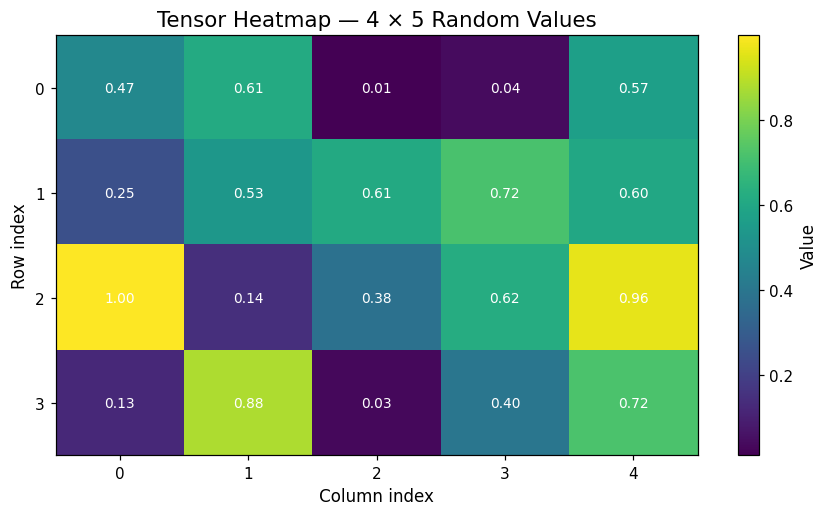

Saved: images/01_tensor_heatmap.png


In [51]:
torch.manual_seed(21)
heatmap_tensor = torch.rand(4, 5)
heatmap_array = heatmap_tensor.numpy()

fig, ax = plt.subplots()
image = ax.imshow(heatmap_array, cmap="viridis", aspect="auto")
ax.set_title("Tensor Heatmap — 4 × 5 Random Values")
ax.set_xlabel("Column index")
ax.set_ylabel("Row index")
ax.set_xticks(range(heatmap_array.shape[1]))
ax.set_yticks(range(heatmap_array.shape[0]))

for row in range(heatmap_array.shape[0]):
    for col in range(heatmap_array.shape[1]):
        ax.text(col, row, f"{heatmap_array[row, col]:.2f}", ha="center", va="center", color="white", fontsize=9)

fig.colorbar(image, ax=ax, label="Value")
fig.tight_layout()
fig.savefig(IMAGES_DIR / "01_tensor_heatmap.png", bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved:", IMAGES_DIR / "01_tensor_heatmap.png")

### 17.2 Compare values with a line plot

This plot visualizes values held in a PyTorch tensor. The conversion to NumPy is safe here because the tensor is on the CPU and is not tracking gradients.

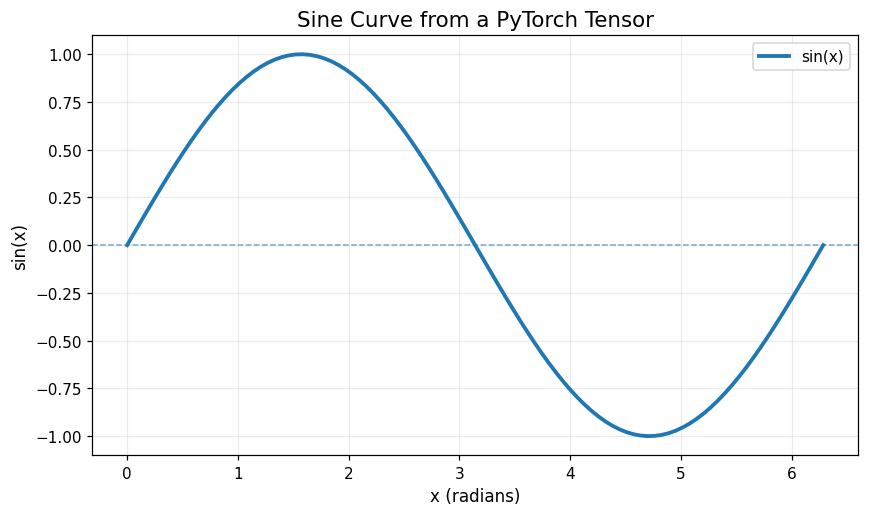

Saved: images/02_tensor_line_plot.png


In [52]:
x_values = torch.linspace(0, 2 * torch.pi, steps=100)
y_values = torch.sin(x_values)

fig, ax = plt.subplots()
ax.plot(x_values.numpy(), y_values.numpy(), linewidth=2.5, label="sin(x)")
ax.axhline(0, linewidth=1, linestyle="--", alpha=0.6)
ax.set_title("Sine Curve from a PyTorch Tensor")
ax.set_xlabel("x (radians)")
ax.set_ylabel("sin(x)")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(IMAGES_DIR / "02_tensor_line_plot.png", bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved:", IMAGES_DIR / "02_tensor_line_plot.png")

### 17.3 Softmax probability bars

Softmax turns a vector of logits into values that sum to one. The bar chart helps show the relative weight of each class.

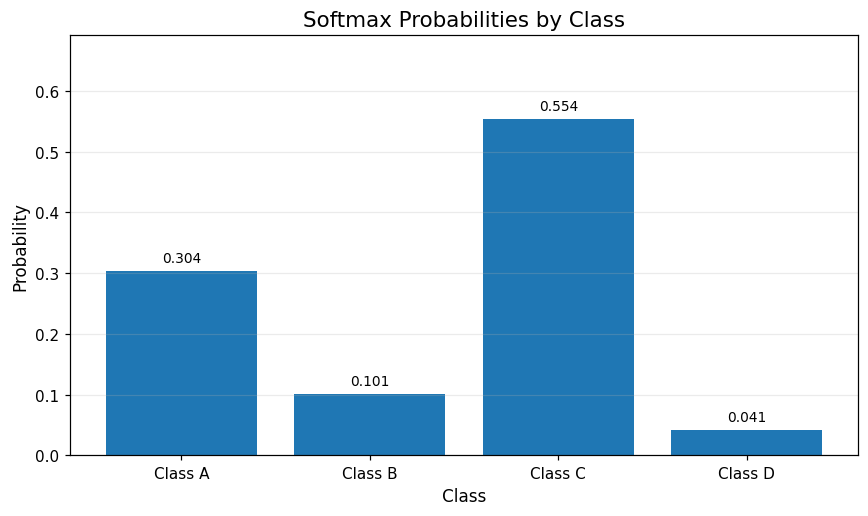

Saved: images/03_softmax_probabilities.png


In [53]:
class_names = ["Class A", "Class B", "Class C", "Class D"]
example_logits = torch.tensor([1.8, 0.7, 2.4, -0.2])
class_probabilities = torch.softmax(example_logits, dim=0)
probabilities_np = class_probabilities.numpy()

fig, ax = plt.subplots()
bars = ax.bar(class_names, probabilities_np)
ax.set_title("Softmax Probabilities by Class")
ax.set_xlabel("Class")
ax.set_ylabel("Probability")
ax.set_ylim(0, max(probabilities_np) * 1.25)
ax.grid(axis="y", alpha=0.25)
for bar, value in zip(bars, probabilities_np):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
            f"{value:.3f}", ha="center", va="bottom", fontsize=9)
fig.tight_layout()
fig.savefig(IMAGES_DIR / "03_softmax_probabilities.png", bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved:", IMAGES_DIR / "03_softmax_probabilities.png")

### Verify the images exist

This final plotting check lists files generated by the visualization cells.

In [54]:
saved_images = sorted(IMAGES_DIR.glob("*.png"))
for image_path in saved_images:
    print(f"{image_path.name:32} {image_path.stat().st_size:>8,} bytes")
print(f"\nTotal saved images: {len(saved_images)}")

01_tensor_heatmap.png              36,043 bytes
02_tensor_line_plot.png            45,565 bytes
03_softmax_probabilities.png       23,439 bytes

Total saved images: 3


# 18. Practical debugging checklist

When a tensor operation fails, inspect the inputs in a consistent order rather than guessing.

| Check | Useful expression | What it tells you |
|---|---|---|
| Shape | `tensor.shape` | The size of each dimension |
| Rank | `tensor.ndim` | Number of dimensions |
| Element count | `tensor.numel()` | Total number of values |
| Data type | `tensor.dtype` | How values are represented |
| Device | `tensor.device` | CPU, CUDA, or another supported device |
| Gradient tracking | `tensor.requires_grad` | Whether operations are tracked for autograd |
| Data values | `tensor` / `tensor.tolist()` | Actual contents (for small tensors) |

**Common causes of errors:** incompatible matrix-multiplication dimensions, incompatible broadcast shapes, mixing CPU and GPU tensors, a dtype that the operation does not support, reshaping to a different element count, or accidentally modifying a view.

In [55]:
# A compact diagnostic helper for learning and debugging.
def describe_tensor(name, tensor):
    """Print a concise summary of a PyTorch tensor."""
    if not isinstance(tensor, torch.Tensor):
        raise TypeError(f"{name} must be a torch.Tensor, got {type(tensor).__name__}")
    print(f"{name}")
    print(f"  shape:         {tuple(tensor.shape)}")
    print(f"  rank:          {tensor.ndim}")
    print(f"  elements:      {tensor.numel()}")
    print(f"  dtype:         {tensor.dtype}")
    print(f"  device:        {tensor.device}")
    print(f"  requires_grad: {tensor.requires_grad}")

example_for_debugging = torch.randn(2, 3, dtype=torch.float32)
describe_tensor("example_for_debugging", example_for_debugging)

example_for_debugging
  shape:         (2, 3)
  rank:          2
  elements:      6
  dtype:         torch.float32
  device:        cpu
  requires_grad: False


# 19. Practice exercises

Try to solve each exercise before viewing its answer. The exercises use only concepts introduced in this notebook.

### Exercise 1 — Create a tensor

Create a 3 × 4 tensor containing the integers from 1 through 12. Print its shape, rank, and number of elements.

In [56]:
# Your solution
exercise_1 = torch.arange(1, 13).reshape(3, 4)
print(exercise_1)
print("shape:", tuple(exercise_1.shape))
print("rank:", exercise_1.ndim)
print("elements:", exercise_1.numel())

tensor([[ 1,  2,  3,  4],
        [ 5,  6,  7,  8],
        [ 9, 10, 11, 12]])
shape: (3, 4)
rank: 2
elements: 12


### Exercise 2 — Index and filter

Using `exercise_1`, print the second row, the final column, and all elements greater than 7.

In [57]:
# Your solution
print("Second row:", exercise_1[1, :])
print("Final column:", exercise_1[:, -1])
print("Values > 7:", exercise_1[exercise_1 > 7])

Second row: tensor([5, 6, 7, 8])
Final column: tensor([ 4,  8, 12])
Values > 7: tensor([ 8,  9, 10, 11, 12])


### Exercise 3 — Reductions

Calculate the sum of each column and the mean of each row. Explain the shapes of the two outputs.

In [58]:
# Your solution
column_sums = exercise_1.sum(dim=0)
row_means = exercise_1.float().mean(dim=1)
print("Column sums:", column_sums, "shape:", tuple(column_sums.shape))
print("Row means:", row_means, "shape:", tuple(row_means.shape))

Column sums: tensor([15, 18, 21, 24]) shape: (4,)
Row means: tensor([ 2.5000,  6.5000, 10.5000]) shape: (3,)


### Exercise 4 — Broadcasting

Create a vector `[100, 200, 300, 400]` and add it to every row of `exercise_1`. Do not use a loop.

In [59]:
# Your solution
offset = torch.tensor([100, 200, 300, 400])
broadcast_result = exercise_1 + offset
print(broadcast_result)

tensor([[101, 202, 303, 404],
        [105, 206, 307, 408],
        [109, 210, 311, 412]])


### Exercise 5 — Matrix multiplication

Create a matrix of shape `(2, 3)` and another of shape `(3, 2)`. Multiply them and confirm that the result has shape `(2, 2)`.

In [60]:
# Your solution
matrix_a = torch.arange(1, 7, dtype=torch.float32).reshape(2, 3)
matrix_b = torch.arange(1, 7, dtype=torch.float32).reshape(3, 2)
matrix_product = matrix_a @ matrix_b
print(matrix_product)
assert tuple(matrix_product.shape) == (2, 2)
print("Shape check passed.")

tensor([[22., 28.],
        [49., 64.]])
Shape check passed.


### Exercise 6 — Copying

Demonstrate the difference between `alias = source` and `source.clone()`. Change one element in each destination and observe which values change.

In [61]:
# Your solution
source = torch.tensor([1, 2, 3])
alias = source
clone = source.clone()

alias[0] = 10
print("Source after editing alias:", source)
clone[1] = 20
print("Source after editing clone:", source)
print("Clone:", clone)

Source after editing alias: tensor([10,  2,  3])
Source after editing clone: tensor([10,  2,  3])
Clone: tensor([ 1, 20,  3])


### Exercise 7 — Autograd

Create `x = 4.0` with `requires_grad=True`, calculate `y = 3*x**2 + 2*x`, then use `backward()` to compute the derivative. Check the result analytically: \(dy/dx = 6x + 2\).

In [62]:
# Your solution
x = torch.tensor(4.0, requires_grad=True)
y = 3 * x**2 + 2 * x
y.backward()
print("y:", y.item())
print("Computed gradient:", x.grad.item())
print("Expected gradient:", 6 * 4 + 2)
assert x.grad.item() == 26.0

y: 56.0
Computed gradient: 26.0
Expected gradient: 26


## Exercise completion checklist

- [ ] I can explain the difference between shape, rank, and number of elements.
- [ ] I can create tensors with specific shapes and dtypes.
- [ ] I can reshape tensors without changing the element count.
- [ ] I can distinguish element-wise multiplication from matrix multiplication.
- [ ] I can explain what `dim=0` and `dim=1` do for a 2-D tensor.
- [ ] I understand when assignment, a view, or a clone shares/copies data.
- [ ] I can inspect dtype and device to diagnose common errors.
- [ ] I can calculate a simple gradient with `autograd`.
- [ ] I can locate the visualization PNGs in the `images/` directory.

# 20. Quick reference

| Goal | Example |
|---|---|
| Create from values | `torch.tensor([[1, 2], [3, 4]])` |
| Create zeros / ones | `torch.zeros(2, 3)` / `torch.ones(2, 3)` |
| Random floats | `torch.rand(2, 3)` |
| Range | `torch.arange(0, 10, 2)` |
| Inspect shape / rank | `x.shape` / `x.ndim` |
| Count values | `x.numel()` |
| Change dtype | `x.to(torch.float32)` |
| Move device | `x.to(device)` |
| Reshape | `x.reshape(rows, columns)` |
| Add dimension | `x.unsqueeze(dim)` |
| Remove size-1 dimensions | `x.squeeze()` |
| Combine on a new axis | `torch.stack((a, b), dim=0)` |
| Join along an existing axis | `torch.cat((a, b), dim=0)` |
| Element-wise multiply | `a * b` |
| Matrix multiply | `a @ b` or `torch.matmul(a, b)` |
| Reduce along an axis | `x.sum(dim=0)` |
| Maximum index | `torch.argmax(x, dim=...)` |
| Conditional select | `torch.where(mask, x, y)` |
| Softmax | `torch.softmax(logits, dim=...)` |
| Independent data copy | `x.clone()` |
| NumPy conversion | `x.detach().cpu().numpy()` |
| Compute gradients | `loss.backward()` |

## Official resources

- [PyTorch — Tensor documentation](https://docs.pytorch.org/docs/stable/tensors.html)
- [PyTorch — Tensor attributes and dtypes](https://docs.pytorch.org/docs/stable/tensor_attributes.html)
- [PyTorch — Tensor creation operations](https://docs.pytorch.org/docs/stable/torch.html#tensor-creation-ops)
- [PyTorch — Automatic differentiation (`autograd`)](https://docs.pytorch.org/docs/stable/autograd.html)
- [PyTorch — Get Started / installation selector](https://pytorch.org/get-started/locally/)

---

**End of notebook.** Re-run the notebook from the top after a kernel restart so all examples have their variables initialized in order.